In [1]:
!pip install -q gensim

In [2]:
import random, re, unicodedata
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
import sklearn, gensim, matplotlib

SEED = 42                      # one seed used everywhere
random.seed(SEED)
np.random.seed(SEED)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| gensim", gensim.__version__, "| matplotlib", matplotlib.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | gensim 4.4.0 | matplotlib 3.10.0


In [3]:
from sklearn.model_selection import train_test_split

# Paste the Raw GitHub link of banglish_sample_dataset.csv between the quotes
URL = "PASTE_YOUR_RAW_GITHUB_LINK_HERE"

try:
    df = pd.read_csv(URL)                               # normal route: public link, no manual setup
except Exception as e:
    print("Link failed, falling back to file upload. Reason:", e)
    from google.colab import files
    uploaded = files.upload()                           # choose banglish_sample_dataset.csv
    df = pd.read_csv(list(uploaded.keys())[0])

print("Columns:", df.columns.tolist())

DROP_3 = True                                           # 3-star reviews are ambiguous
if DROP_3:
    df = df[df["rating"] != 3]
df["label"] = (df["rating"] > 3).astype(int)            # 1 = positive (4-5 stars), 0 = negative (1-2 stars)
df["text"] = df["text"].astype(str).str.strip()

df["key"] = df["text"].str.lower()                      # exact duplicates removed BEFORE splitting
df = df.drop_duplicates("key").drop(columns="key").reset_index(drop=True)
print("Documents after cleaning:", len(df))

# Stratified 70/15/15 split with a fixed seed
train, temp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp["label"], random_state=SEED)
print("train / val / test:", len(train), len(val), len(test))

Link failed, falling back to file upload. Reason: [Errno 2] No such file or directory: 'PASTE_YOUR_RAW_GITHUB_LINK_HERE'


Saving banglish_sample_dataset.csv to banglish_sample_dataset.csv
Columns: ['text', 'rating', 'label']
Documents after cleaning: 13591
train / val / test: 9513 2039 2039


train n= 9513 | negative=0.264, positive=0.736
val   n= 2039 | negative=0.264, positive=0.736
test  n= 2039 | negative=0.264, positive=0.736


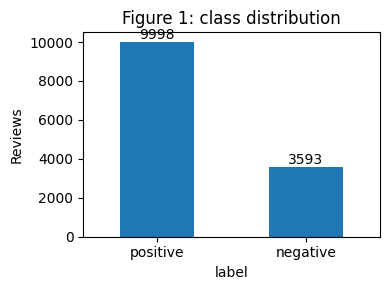

Interpretation: the data is imbalanced (positive is 2.8x more frequent), so accuracy can mislead and macro-F1 is the primary metric.


In [4]:
CLASS_NAMES = {0: "negative", 1: "positive"}

for name, d in [("train", train), ("val", val), ("test", test)]:
    ratios = d["label"].value_counts(normalize=True).sort_index()
    print(f"{name:5s} n={len(d):5d} | " + ", ".join(f"{CLASS_NAMES[k]}={v:.3f}" for k, v in ratios.items()))

counts = df["label"].map(CLASS_NAMES).value_counts()
fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, rot=0)
ax.set_title("Figure 1: class distribution"); ax.set_ylabel("Reviews")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

ratio = counts.max() / counts.min()
print(f"Interpretation: the data is imbalanced ({counts.idxmax()} is {ratio:.1f}x more frequent), so accuracy can mislead and macro-F1 is the primary metric.")

           count  mean   std  min  25%   50%   75%    max
label                                                    
negative  2515.0  13.7  12.4  2.0  6.0  10.0  17.0  143.0
positive  6998.0  10.6   9.5  1.0  5.0   8.0  13.0  128.0


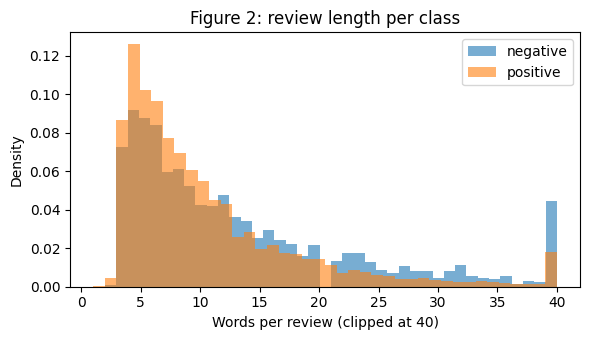

Interpretation: reviews are short (median 10 words for negative, 8 for positive), so each review carries little context.


In [5]:
tr = train.copy()
tr["n_words"] = tr["text"].str.split().str.len()
print(tr.groupby("label")["n_words"].describe().round(1).rename(index=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(6, 3.5))
for lab in (0, 1):
    ax.hist(tr.loc[tr.label == lab, "n_words"].clip(upper=40), bins=40, alpha=0.6, density=True, label=CLASS_NAMES[lab])
ax.set_xlabel("Words per review (clipped at 40)"); ax.set_ylabel("Density")
ax.set_title("Figure 2: review length per class"); ax.legend()
plt.tight_layout(); plt.show()

med = tr.groupby("label")["n_words"].median()
print(f"Interpretation: reviews are short (median {med[0]:.0f} words for negative, {med[1]:.0f} for positive), so each review carries little context.")

In [11]:
# Common emoji ranges (used only when emoji="keep")
EMOJI_PAT = "[\U0001F000-\U0001FAFF\u2600-\u27BF]"

# Stop-words from the top-frequency list. Kept on purpose: na, nai, nei (negation), kintu, but (contrast), kom, faltu, nosto
STOP = {"ta","ti","te","e","er","o","r","ar","a","k","ke","ki","je","ei","oi","eta","ota","ekta","akta",
        "kore","hoy","hoi","hoye","ase","ache","achhe","jonno","niye","theke","diye","tai",
        "and","the","is","you"}

# Spelling-variant map: merges different spellings of the same word
VARIANTS = {
    "vlo":"valo","bhalo":"valo","vallo":"valo","valoi":"valo",                 # "good"
    "onk":"onek","onak":"onek","onaki":"onek","khubi":"khub",                  # "very / a lot"
    "cilo":"chilo","amr":"amar",                                               # "was", "my"
    "tnx":"thanks","tnq":"thanks","thank":"thanks","daraj":"daraz",            # thanks / daraz
    "prodak":"product","produkt":"product","producet":"product","prodact":"product","products":"product",
    "r":"ar","k":"ke","a":"e","paisi":"peyechi","pareb":"paren",               # short forms
    "sundor":"shundor","shunddor":"shundor",
}

def preprocess(text, emoji="remove", stopwords=False, normalize=True, collapse=True):
    """
    emoji     : 'remove' or 'keep' (emojis kept as separate tokens)
    stopwords : remove words in STOP
    normalize : map spelling variants using VARIANTS
    collapse  : shorten letter elongation ('valooo' -> 'valoo')
    """
    t = unicodedata.normalize("NFKC", str(text)).lower()   # unicode normalisation + case folding
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)           # URLs
    t = re.sub(r"<[^>]+>", " ", t)                         # HTML tags
    t = re.sub(r"@\w+", " ", t)                            # user handles
    t = t.replace("\ufe0f", " ").replace("\u200d", " ")    # emoji variation selectors
    t = re.sub(r"\d+", " ", t)                             # numbers
    if collapse:
        t = re.sub(r"(.)\1{2,}", r"\1\1", t)               # 3+ repeated letters -> 2
    pat = r"[^\W\d_]+" + (f"|{EMOJI_PAT}" if emoji == "keep" else "")
    tokens = re.findall(pat, t)                            # letters (and emoji if kept); punctuation is dropped
    if normalize:
        tokens = [VARIANTS.get(w, w) for w in tokens]      # variants first ...
    if stopwords:
        tokens = [w for w in tokens if w not in STOP]      # ... then stop-words
    return " ".join(tokens)

# Quick test on 8 random training reviews
for s in train["text"].sample(8, random_state=1):
    print("RAW  :", s)
    print("CLEAN:", preprocess(s, emoji="keep", stopwords=True), "\n")

RAW  : T shart tikase kintu dowar por colour ute jai.
CLEAN: t shart tikase kintu dowar por colour ute jai 

RAW  : Facewash Ta Valo Face Ekdom Clean Hoye Jay..
CLEAN: facewash valo face ekdom clean jay 

RAW  : eta Bangla Mal likha Spanish countryr full vowa
CLEAN: bangla mal likha spanish countryr full vowa 

RAW  : valo chilo..Free Roshi gola aro 1tu Lomba dile valo hoito
CLEAN: valo chilo free roshi gola aro tu lomba dile valo hoito 

RAW  : ghorita jamon dakhaci tamon payaci
CLEAN: ghorita jamon dakhaci tamon payaci 

RAW  : Nice quality.Valo legeche.
CLEAN: nice quality valo legeche 

RAW  : nice producet nite pareb
CLEAN: nice product nite paren 

RAW  : Masha Allah! khub valo
CLEAN: masha allah khub valo 



In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

# Majority-class baseline sanity check (majority class taken from TRAIN)
dummy = DummyClassifier(strategy="most_frequent").fit(train["text"], train["label"])
print("Majority baseline val macro-F1:", round(f1_score(val["label"], dummy.predict(val["text"]), average="macro"), 4))

PREP_CONFIGS = {
    "A minimal (no collapse/normalise, emoji removed)": dict(emoji="remove", stopwords=False, normalize=False, collapse=False),
    "B full cleaning, emoji removed":                  dict(emoji="remove", stopwords=False),
    "C full cleaning, emoji kept":                     dict(emoji="keep",   stopwords=False),
    "D emoji removed + stop-words removed":            dict(emoji="remove", stopwords=True),
    "E emoji kept + stop-words removed":               dict(emoji="keep",   stopwords=True),
}

rows = []
for name, cfg in PREP_CONFIGS.items():
    tr_txt = train["text"].apply(lambda s: preprocess(s, **cfg))
    va_txt = val["text"].apply(lambda s: preprocess(s, **cfg))
    vec = TfidfVectorizer(ngram_range=(1, 1), min_df=2, token_pattern=r"\S+")   # fitted on TRAIN only
    Xtr, Xva = vec.fit_transform(tr_txt), vec.transform(va_txt)
    for mname, model in [("MultinomialNB", MultinomialNB(alpha=1.0)),
                         ("LogReg", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))]:
        model.fit(Xtr, train["label"])
        rows.append((name, mname, round(f1_score(val["label"], model.predict(Xva), average="macro"), 4)))

abl = pd.DataFrame(rows, columns=["pipeline", "model", "val_macro_F1"]).pivot(index="pipeline", columns="model", values="val_macro_F1")
print(abl)
abl.to_csv("ablation_val.csv")

# Final preprocessing = best variant by validation macro-F1 with Logistic Regression
best_name = abl["LogReg"].idxmax()
BEST_CFG = PREP_CONFIGS[best_name]
print("Selected pipeline:", best_name, BEST_CFG)

Majority baseline val macro-F1: 0.4238
model                                             LogReg  MultinomialNB
pipeline                                                               
A minimal (no collapse/normalise, emoji removed)  0.8020         0.7699
B full cleaning, emoji removed                    0.8028         0.7745
C full cleaning, emoji kept                       0.8079         0.7818
D emoji removed + stop-words removed              0.8017         0.7675
E emoji kept + stop-words removed                 0.8068         0.7742
Selected pipeline: C full cleaning, emoji kept {'emoji': 'keep', 'stopwords': False}


In [13]:
# ---------- 4.3 Apply the selected pipeline to every split ----------
# TEMPORARY SAFETY: only used if the Section 4.2 ablation cell was not run in this session.
# You must still run the 4.2 ablation cell later, because the report needs its table.
if "BEST_CFG" not in globals():
    BEST_CFG = dict(emoji="keep", stopwords=False)      # variant C, the validation winner in earlier runs
    print("WARNING: BEST_CFG was missing, using variant C. Run the 4.2 ablation cell to confirm.")

assert "preprocess" in globals(), "preprocess is missing: run the Section 4.1 cell first"

print("Final preprocessing config:", BEST_CFG)
train, val, test = train.copy(), val.copy(), test.copy()
for d in (train, val, test):
    d["clean"] = d["text"].apply(lambda s: preprocess(s, **BEST_CFG))   # cleaned string
    d["tokens"] = d["clean"].str.split()                                # token list (for Word2Vec)

for name, d in [("train", train), ("val", val), ("test", test)]:
    n_empty = (d["clean"].str.len() == 0).sum()
    print(f"{name}: {len(d)} docs | empty after cleaning: {n_empty} | "
          f"avg tokens before {d['text'].str.split().str.len().mean():.1f} -> after {d['tokens'].str.len().mean():.1f}")
print("Train vocabulary size:", len(set(w for toks in train["tokens"] for w in toks)))

ytr, yva, yte = train["label"].values, val["label"].values, test["label"].values

Final preprocessing config: {'emoji': 'keep', 'stopwords': False}
train: 9513 docs | empty after cleaning: 0 | avg tokens before 11.4 -> after 11.8
val: 2039 docs | empty after cleaning: 0 | avg tokens before 11.4 -> after 11.7
test: 2039 docs | empty after cleaning: 0 | avg tokens before 11.3 -> after 11.6
Train vocabulary size: 11617


NEGATIVE BEFORE: [('na', 592), ('valo', 530), ('ta', 517), ('product', 458), ('er', 401), ('e', 310), ('baje', 306), ('r', 261), ('ki', 245), ('order', 240), ('ami', 223), ('ar', 221)]
NEGATIVE AFTER : [('na', 915), ('valo', 786), ('product', 673), ('ta', 590), ('ar', 518), ('e', 412), ('er', 411), ('nai', 385), ('baje', 367), ('onek', 348), ('chilo', 303), ('ki', 279)] 

POSITIVE BEFORE: [('valo', 2950), ('ta', 1452), ('product', 1370), ('onek', 1208), ('onk', 1153), ('khub', 975), ('nite', 822), ('daraz', 747), ('vlo', 706), ('e', 647), ('paren', 629), ('o', 553)]
POSITIVE AFTER : [('valo', 4880), ('onek', 2652), ('product', 2190), ('ta', 1571), ('thanks', 1223), ('khub', 1198), ('chilo', 1113), ('daraz', 987), ('paren', 976), ('e', 946), ('nite', 859), ('ar', 683)] 



/tmp/ipykernel_2541/265933748.py:16: UserWarning: Glyph 129392 (\N{SMILING FACE WITH SMILING EYES AND THREE HEARTS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129392 (\N{SMILING FACE WITH SMILING EYES AND THREE HEARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


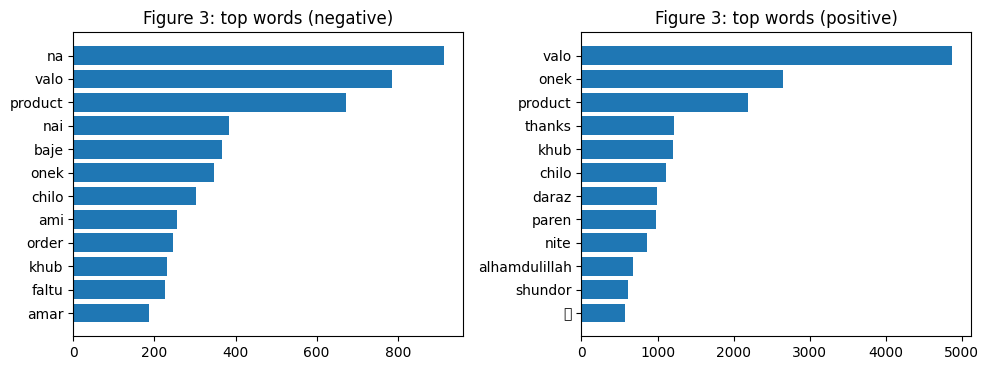

Interpretation: after preprocessing, the most frequent content words are ('na', 'valo', 'product') for negative and ('valo', 'onek', 'product') for positive reviews.


In [14]:
def top_words(texts, n=12):
    return Counter(w for s in texts for w in s.split()).most_common(n)

for lab in (0, 1):
    print(CLASS_NAMES[lab].upper(), "BEFORE:", top_words(train.loc[train.label == lab, "text"].str.lower()))
    print(CLASS_NAMES[lab].upper(), "AFTER :", top_words(train.loc[train.label == lab, "clean"]), "\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
tops = {}
for ax, lab in zip(axes, (0, 1)):
    c = Counter(w for s in train.loc[train.label == lab, "clean"] for w in s.split() if w not in STOP)
    w, n = zip(*c.most_common(12))
    tops[lab] = w[:3]
    ax.barh(w[::-1], n[::-1])
    ax.set_title(f"Figure 3: top words ({CLASS_NAMES[lab]})")
plt.tight_layout(); plt.show()
print(f"Interpretation: after preprocessing, the most frequent content words are {tops[0]} for negative and {tops[1]} for positive reviews.")

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

def macro_f1(y, p):
    return f1_score(y, p, average="macro")

REPS = {
    "BoW (unigram)":        lambda: CountVectorizer(ngram_range=(1, 1), min_df=2, token_pattern=r"\S+"),
    "TF-IDF (unigram)":     lambda: TfidfVectorizer(ngram_range=(1, 1), min_df=2, token_pattern=r"\S+"),
    "TF-IDF (uni+bigram)":  lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\S+"),
}
NB_ALPHAS = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0]                                     # smoothing grid
LR_GRID = [(C, cw) for C in [0.1, 0.3, 1, 3, 10, 30] for cw in [None, "balanced"]]    # C and class weight

FROZEN = {}   # name -> dict(kind, vec, model, val_f1, params)

# Majority-class baseline (majority class taken from TRAIN)
base = DummyClassifier(strategy="most_frequent").fit(train["clean"], ytr)
FROZEN["Majority baseline"] = dict(kind="sparse", vec=None, model=base,
                                   val_f1=macro_f1(yva, base.predict(val["clean"])), params={})

for rname, make_vec in REPS.items():
    vec = make_vec()
    Xtr = vec.fit_transform(train["clean"])          # fit on train only
    Xva = vec.transform(val["clean"])
    print(f"{rname}: {Xtr.shape[1]} features")

    best = None                                      # Multinomial NB: tune alpha on validation
    for a in NB_ALPHAS:
        m = MultinomialNB(alpha=a).fit(Xtr, ytr)
        f = macro_f1(yva, m.predict(Xva))
        if best is None or f > best[0]:
            best = (f, a, m)
    FROZEN[f"{rname} + MultinomialNB"] = dict(kind="sparse", vec=vec, model=best[2],
                                              val_f1=best[0], params={"alpha": best[1]})

    best = None                                      # Logistic Regression: tune C and class_weight
    for C, cw in LR_GRID:
        m = LogisticRegression(C=C, class_weight=cw, solver="liblinear", max_iter=1000, random_state=SEED).fit(Xtr, ytr)
        f = macro_f1(yva, m.predict(Xva))
        if best is None or f > best[0]:
            best = (f, (C, cw), m)
    FROZEN[f"{rname} + LogReg"] = dict(kind="sparse", vec=vec, model=best[2],
                                       val_f1=best[0], params={"C": best[1][0], "class_weight": best[1][1]})

for k, v in FROZEN.items():
    print(f"{k:38s} val macro-F1 = {v['val_f1']:.4f}  {v['params']}")

BoW (unigram): 4741 features
TF-IDF (unigram): 4741 features
TF-IDF (uni+bigram): 13945 features
Majority baseline                      val macro-F1 = 0.4238  {}
BoW (unigram) + MultinomialNB          val macro-F1 = 0.8315  {'alpha': 0.5}
BoW (unigram) + LogReg                 val macro-F1 = 0.8341  {'C': 0.3, 'class_weight': 'balanced'}
TF-IDF (unigram) + MultinomialNB       val macro-F1 = 0.8014  {'alpha': 0.5}
TF-IDF (unigram) + LogReg              val macro-F1 = 0.8320  {'C': 1, 'class_weight': 'balanced'}
TF-IDF (uni+bigram) + MultinomialNB    val macro-F1 = 0.8296  {'alpha': 0.05}
TF-IDF (uni+bigram) + LogReg           val macro-F1 = 0.8472  {'C': 3, 'class_weight': 'balanced'}


In [16]:
from gensim.models import Word2Vec
from sklearn.naive_bayes import GaussianNB

w2v = Word2Vec(sentences=train["tokens"].tolist(), vector_size=100, window=5, min_count=2,
               sg=1, epochs=10, workers=1, seed=SEED)       # workers=1 + seed for reproducibility
print("Word2Vec vocabulary:", len(w2v.wv))
if "valo" in w2v.wv:                                         # sanity check: neighbours of 'valo' (good)
    print("Nearest to 'valo':", [w for w, _ in w2v.wv.most_similar("valo", topn=6)])

def doc_vector(tokens):
    """Average of in-vocabulary token vectors; zero vector if no token is known."""
    vecs = [w2v.wv[t] for t in tokens if t in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

Wtr = np.vstack(train["tokens"].apply(doc_vector))
Wva = np.vstack(val["tokens"].apply(doc_vector))

best = None                                                  # Logistic Regression
for C, cw in [(C, cw) for C in [0.1, 1, 10, 100] for cw in [None, "balanced"]]:
    m = LogisticRegression(C=C, class_weight=cw, solver="liblinear", max_iter=1000, random_state=SEED).fit(Wtr, ytr)
    f = macro_f1(yva, m.predict(Wva))
    if best is None or f > best[0]:
        best = (f, (C, cw), m)
FROZEN["Word2Vec avg + LogReg"] = dict(kind="dense", vec=None, model=best[2],
                                       val_f1=best[0], params={"C": best[1][0], "class_weight": best[1][1]})

best = None                                                  # Optional: Gaussian NB
for vs in [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]:
    m = GaussianNB(var_smoothing=vs).fit(Wtr, ytr)
    f = macro_f1(yva, m.predict(Wva))
    if best is None or f > best[0]:
        best = (f, vs, m)
FROZEN["Word2Vec avg + GaussianNB (optional)"] = dict(kind="dense", vec=None, model=best[2],
                                                      val_f1=best[0], params={"var_smoothing": best[1]})

summary = pd.DataFrame([(k, v["val_f1"], v["params"]) for k, v in FROZEN.items()],
                       columns=["configuration", "val_macro_F1", "best_params"]).sort_values("val_macro_F1", ascending=False)
print(summary.to_string(index=False))

# The best model is selected on VALIDATION macro-F1 (the baseline is excluded)
BEST_NAME = summary[~summary["configuration"].str.contains("Majority")].iloc[0]["configuration"]
print("\nBest on validation:", BEST_NAME)

Word2Vec vocabulary: 4954
Nearest to 'valo': ['vhalo', 'balo', 'sondor', 'maner', 'better', 'shundor']
                       configuration  val_macro_F1                            best_params
        TF-IDF (uni+bigram) + LogReg      0.847240   {'C': 3, 'class_weight': 'balanced'}
              BoW (unigram) + LogReg      0.834081 {'C': 0.3, 'class_weight': 'balanced'}
           TF-IDF (unigram) + LogReg      0.832014   {'C': 1, 'class_weight': 'balanced'}
       BoW (unigram) + MultinomialNB      0.831494                         {'alpha': 0.5}
 TF-IDF (uni+bigram) + MultinomialNB      0.829601                        {'alpha': 0.05}
               Word2Vec avg + LogReg      0.827892 {'C': 100, 'class_weight': 'balanced'}
    TF-IDF (unigram) + MultinomialNB      0.801378                         {'alpha': 0.5}
Word2Vec avg + GaussianNB (optional)      0.777089                 {'var_smoothing': 0.1}
                   Majority baseline      0.423849                                     

         Representation + classifier  Accuracy  Macro-P  Macro-R  Macro-F1 (test)  Macro-F1 (val)
                   Majority baseline    0.7357   0.3678   0.5000           0.4238          0.4238
       BoW (unigram) + MultinomialNB    0.8529   0.8099   0.8150           0.8124          0.8315
              BoW (unigram) + LogReg    0.8499   0.8046   0.8415           0.8188          0.8341
    TF-IDF (unigram) + MultinomialNB    0.8440   0.8102   0.7704           0.7864          0.8014
           TF-IDF (unigram) + LogReg    0.8504   0.8057   0.8484           0.8212          0.8320
 TF-IDF (uni+bigram) + MultinomialNB    0.8656   0.8256   0.8332           0.8293          0.8296
        TF-IDF (uni+bigram) + LogReg    0.8597   0.8158   0.8482           0.8290          0.8472
               Word2Vec avg + LogReg    0.8367   0.7921   0.8409           0.8078          0.8279
Word2Vec avg + GaussianNB (optional)    0.7979   0.7574   0.8133           0.7696          0.7771

Validation-selected

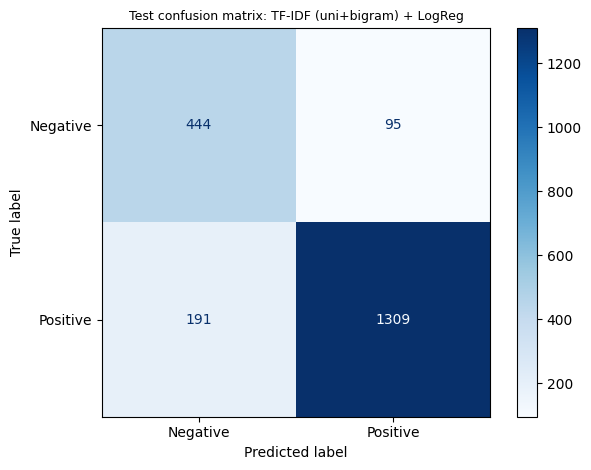

              precision    recall  f1-score   support

    Negative     0.6992    0.8237    0.7564       539
    Positive     0.9323    0.8727    0.9015      1500

    accuracy                         0.8597      2039
   macro avg     0.8158    0.8482    0.8290      2039
weighted avg     0.8707    0.8597    0.8632      2039



In [17]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

Wte = np.vstack(test["tokens"].apply(doc_vector))      # test embeddings use the TRAIN-only Word2Vec

rows, TEST_PRED = [], {}
for name, v in FROZEN.items():
    if name == "Majority baseline":
        Xte = test["clean"]
    elif v["kind"] == "sparse":
        Xte = v["vec"].transform(test["clean"])         # vectoriser fitted on train only
    else:
        Xte = Wte
    pred = v["model"].predict(Xte)
    TEST_PRED[name] = pred
    rows.append((name,
                 accuracy_score(yte, pred),
                 precision_score(yte, pred, average="macro", zero_division=0),
                 recall_score(yte, pred, average="macro"),
                 f1_score(yte, pred, average="macro"),
                 v["val_f1"]))

results = pd.DataFrame(rows, columns=["Representation + classifier", "Accuracy", "Macro-P", "Macro-R",
                                      "Macro-F1 (test)", "Macro-F1 (val)"]).round(4)
print(results.to_string(index=False))
results.to_csv("results_test.csv", index=False)

print("\nValidation-selected model:", BEST_NAME)
cm = confusion_matrix(yte, TEST_PRED[BEST_NAME])
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues", values_format="d")
plt.title(f"Test confusion matrix: {BEST_NAME}", fontsize=9); plt.tight_layout(); plt.show()
print(classification_report(yte, TEST_PRED[BEST_NAME], target_names=["Negative", "Positive"], digits=4))

In [18]:
# (a) Top-10 informative words per class from Multinomial NB
nb_names = [k for k in FROZEN if "MultinomialNB" in k]
nb_best = max(nb_names, key=lambda k: FROZEN[k]["val_f1"])          # NB model with the best validation macro-F1
vec, nb = FROZEN[nb_best]["vec"], FROZEN[nb_best]["model"]
print("Naive Bayes model used:", nb_best)

words = np.array(vec.get_feature_names_out())
doc_freq = np.asarray((vec.transform(train["clean"]) > 0).sum(axis=0)).ravel()
ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]           # log P(w|positive) - log P(w|negative)
idx = np.where(doc_freq >= 5)[0]                                     # ignore very rare words
order = idx[np.argsort(ratio[idx])]
top1, top0 = order[::-1][:10], order[:10]
print(f"\nTop 10 words for {CLASS_NAMES[1]}:", list(zip(words[top1].tolist(), ratio[top1].round(2).tolist())))
print(f"Top 10 words for {CLASS_NAMES[0]}:", list(zip(words[top0].tolist(), ratio[top0].round(2).tolist())))

# (b) Misclassified TEST examples of the validation-selected model
te = test.copy()
te["pred"] = TEST_PRED[BEST_NAME]
errors = te[te["label"] != te["pred"]].copy()
print(f"\n{len(errors)} errors out of {len(te)} | "
      f"false positives (true {CLASS_NAMES[0]} -> pred {CLASS_NAMES[1]}): {(errors.label == 0).sum()} | "
      f"false negatives: {(errors.label == 1).sum()}")
if "rating" in errors.columns:
    print("Errors by star rating:\n", errors["rating"].value_counts().sort_index())

def hints(s):
    t = s.lower().split(); f = []
    if any(w in t for w in ["na", "nai", "nei", "noy", "nay"]):   f.append("negation")
    if any(w in t for w in ["but", "kintu", "tobe"]):             f.append("contrast")
    if re.search(EMOJI_PAT, s):                                   f.append("emoji")
    if len(t) <= 3:                                               f.append("very-short")
    return ",".join(f)

sample = errors.sample(min(30, len(errors)), random_state=SEED).copy()
sample["hints"] = sample["text"].apply(hints)
sample["error_type"] = ""                                            # fill this column by hand
cols = [c for c in ["text", "rating", "label", "pred", "hints", "error_type"] if c in sample.columns]
pd.set_option("display.max_colwidth", 160, "display.width", 250)
print(sample[cols].to_string())
sample[cols].to_csv("error_analysis_30.csv", index=False)

Naive Bayes model used: BoW (unigram) + MultinomialNB

Top 10 words for positive: [('peyesi', 4.51), ('joss', 4.17), ('dhonnobad', 3.71), ('😍', 3.64), ('😇', 3.63), ('thnx', 3.58), ('😁', 3.58), ('osadharon', 3.55), ('🤩', 3.5), ('❣', 3.47)]
Top 10 words for negative: [('ekebare', -3.9), ('please', -3.9), ('ulta', -3.81), ('aisob', -3.81), ('kinen', -3.71), ('noshto', -3.6), ('joghonno', -3.6), ('display', -3.6), ('vora', -3.6), ('eitar', -3.6)]

286 errors out of 2039 | false positives (true negative -> pred positive): 95 | false negatives: 191
Errors by star rating:
 rating
1     58
2     37
4     38
5    153
Name: count, dtype: int64
                                                                                                                                                                                                   text  rating  label  pred              hints error_type
10973                                                                                                      

In [19]:
out = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
out[["split", "text", "clean", "rating", "label"]].to_csv("daraz_preprocessed.csv", index=False, encoding="utf-8")

best_row = results[results["Representation + classifier"] == BEST_NAME].iloc[0]
print("Selected preprocessing:", best_name)
print("Validation-selected model:", BEST_NAME, FROZEN[BEST_NAME]["params"])
print(f"Test: accuracy={best_row['Accuracy']}, macro-P={best_row['Macro-P']}, macro-R={best_row['Macro-R']}, macro-F1={best_row['Macro-F1 (test)']}")
print("Majority baseline test macro-F1:", results.loc[results["Representation + classifier"] == "Majority baseline", "Macro-F1 (test)"].iloc[0])

try:                                                    # downloads work only in Colab
    from google.colab import files
    for f in ["results_test.csv", "ablation_val.csv", "error_analysis_30.csv", "daraz_preprocessed.csv"]:
        files.download(f)
except ImportError:
    print("Not running in Colab: files were saved in the working folder.")

Selected preprocessing: C full cleaning, emoji kept
Validation-selected model: TF-IDF (uni+bigram) + LogReg {'C': 3, 'class_weight': 'balanced'}
Test: accuracy=0.8597, macro-P=0.8158, macro-R=0.8482, macro-F1=0.829
Majority baseline test macro-F1: 0.4238


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>